# Deep Learning PR 3 
### Red & White Skill Education
**Topics:** Morphological Operations · Bitwise Operations · Histograms · Face Detection (YuNet) · YOLOv8 Object Detection

This notebook completes **Tasks 1–5** from the PR-3 project sheet.

### Pipeline
**Classical image processing → Face detection → Deep-learning object detection → Integrated comparison**

### Materials used
- Programmatically generated synthetic images for morphology and bitwise experiments.
- OpenCV's public sample `lena.jpg` for YuNet face detection.
- Ultralytics public sample `bus.jpg` for YOLO object detection.
- Models are downloaded automatically by the notebook when needed.

> **Note:** Webcam cells are optional. If a webcam is unavailable, the notebook uses a video-file fallback.

In [1]:
# ============================================================
# 1. ENVIRONMENT SETUP
# ============================================================
# Run this cell once in a fresh environment.
# In VS Code/Jupyter, restart the kernel after installation if requested.

%pip install -q "opencv-contrib-python==5.0.0.0" ultralytics matplotlib numpy pandas requests

import os
import sys
import time
import urllib.request
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("OpenCV:", cv2.__version__)

assert tuple(map(int, cv2.__version__.split(".")[:2])) >= (5, 0), "OpenCV 5.x is required."

BASE = Path.cwd()
DATA = BASE / "data"
IMAGES = DATA / "images"
MODELS = DATA / "models"
OUTPUTS = DATA / "outputs"

for p in [IMAGES, MODELS, OUTPUTS]:
    p.mkdir(parents=True, exist_ok=True)

print("Image folder :", IMAGES.resolve())
print("Model folder :", MODELS.resolve())
print("Output folder:", OUTPUTS.resolve())

ERROR: Could not find a version that satisfies the requirement opencv-contrib-python==5.0.0.0 (from versions: 3.4.11.45, 3.4.13.47, 3.4.14.51, 3.4.15.55, 3.4.16.59, 3.4.17.61, 3.4.17.63, 3.4.18.65, 4.4.0.46, 4.5.1.48, 4.5.2.52, 4.5.3.56, 4.5.4.58, 4.5.4.60, 4.5.5.62, 4.5.5.64, 4.6.0.66, 4.7.0.68, 4.7.0.72, 4.8.0.74, 4.8.0.76, 4.8.1.78, 4.9.0.80, 4.10.0.82, 4.10.0.84, 4.11.0.86, 4.12.0.88, 4.13.0.90, 4.13.0.92, 4.14.0.94, 5.0.0.93)
ERROR: No matching distribution found for opencv-contrib-python==5.0.0.0


Note: you may need to restart the kernel to use updated packages.
Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
OpenCV: 5.0.0
Image folder : D:\deep learning\pr 3\New folder\CV_PR3_Deep_Learning_PR3\data\images
Model folder : D:\deep learning\pr 3\New folder\CV_PR3_Deep_Learning_PR3\data\models
Output folder: D:\deep learning\pr 3\New folder\CV_PR3_Deep_Learning_PR3\data\outputs


## Helper functions

The helper below displays BGR OpenCV images correctly in Matplotlib and keeps the notebook output consistent.

In [2]:
def show(img, title="", figsize=(8, 5), cmap=None):
    plt.figure(figsize=figsize)
    if img.ndim == 3 and cmap is None:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap)
    plt.title(title)
    plt.axis("off")
    plt.show()

def show_grid(items, cols=3, figsize=(14, 9)):
    rows = int(np.ceil(len(items) / cols))
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(items, 1):
        ax = plt.subplot(rows, cols, i)
        if img.ndim == 3:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(img, cmap="gray")
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def download_file(url, path):
    path = Path(path)
    if not path.exists():
        print("Downloading:", url)
        urllib.request.urlretrieve(url, path)
    return path

print("Helpers ready.")

Helpers ready.


# Task 1 — Environment Setup, Image I/O & Morphological Operations

## 1.1 Environment setup & image loading

We create our own test images so the classical image-processing part does not depend on a user's local dataset.

shape: (420, 620, 3)
dtype: uint8


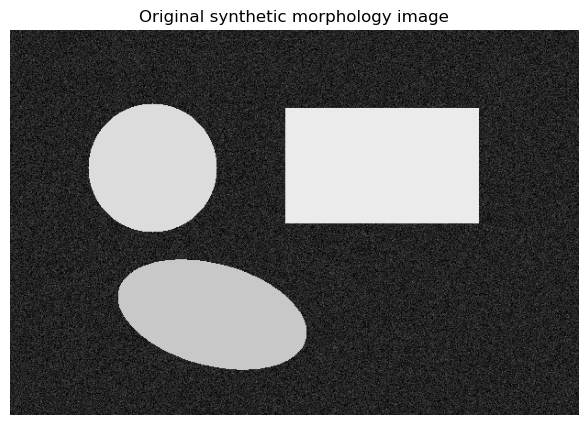

In [7]:
# Create an original synthetic image: textured/noisy background + solid objects.
rng = np.random.default_rng(42)

h, w = 420, 620
base = np.full((h, w, 3), 35, dtype=np.uint8)

# Mild textured background
noise = rng.normal(0, 18, (h, w, 1)).astype(np.int16)
texture = np.clip(base.astype(np.int16) + noise, 0, 255).astype(np.uint8)

# Add simple bright objects
cv2.circle(texture, (155, 150), 70, (220, 220, 220), -1)
cv2.rectangle(texture, (300, 85), (510, 210), (235, 235, 235), -1)
cv2.ellipse(texture, (220, 310), (105, 55), 15, 0, 360, (200, 200, 200), -1)

original = texture
cv2.imwrite(str(IMAGES / "morphology_test.png"), original)

print("shape:", original.shape)
print("dtype:", original.dtype)
show(original, "Original synthetic morphology image")

### 1.2 Binarize a test image

Thresholding converts the grayscale image into a binary mask. This mask is the input for the morphology experiments.

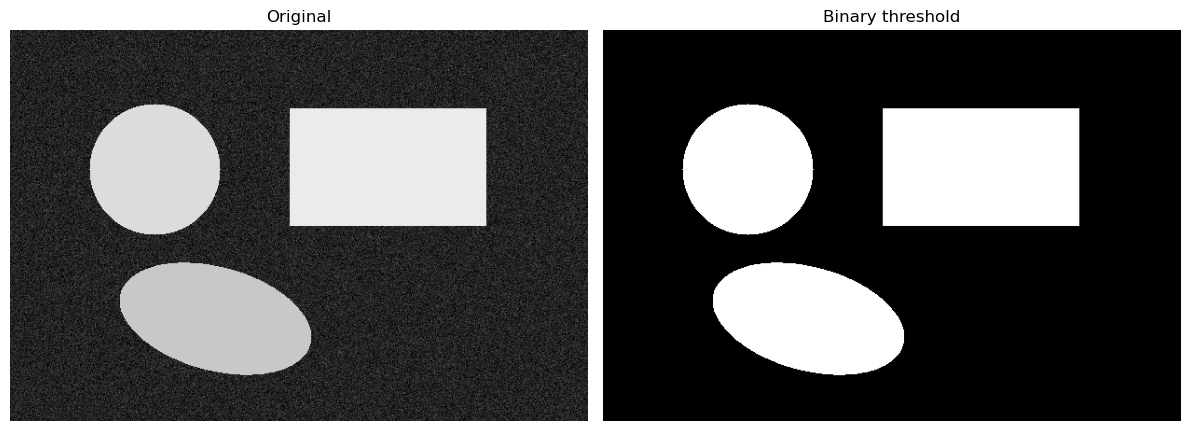

True

In [8]:
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
_, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

show_grid([
    (original, "Original"),
    (binary, "Binary threshold")
], cols=2, figsize=(12, 5))

cv2.imwrite(str(OUTPUTS / "01_binary.png"), binary)

### 1.3 Apply the four morphological operations

A 5×5 rectangular kernel is used.

- **Erosion:** shrinks white regions.
- **Dilation:** expands white regions.
- **Opening:** erosion followed by dilation; useful for removing small bright noise.
- **Closing:** dilation followed by erosion; useful for filling small holes.

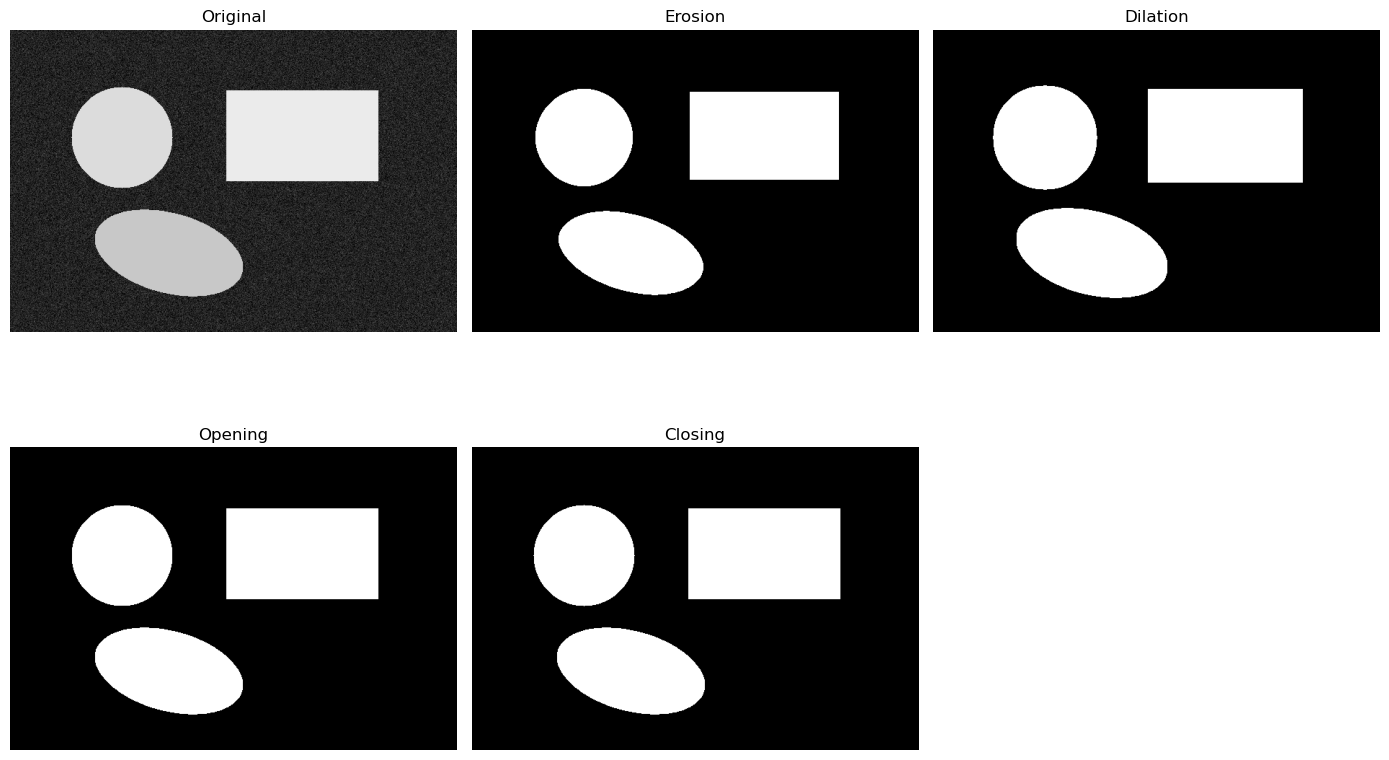

True

In [9]:
kernel = np.ones((5, 5), np.uint8)

erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

show_grid([
    (original, "Original"),
    (erosion, "Erosion"),
    (dilation, "Dilation"),
    (opening, "Opening"),
    (closing, "Closing")
], cols=3)

cv2.imwrite(str(OUTPUTS / "02_erosion.png"), erosion)
cv2.imwrite(str(OUTPUTS / "03_dilation.png"), dilation)
cv2.imwrite(str(OUTPUTS / "04_opening.png"), opening)
cv2.imwrite(str(OUTPUTS / "05_closing.png"), closing)

### 1.4 Kernel shape & size comparison

We compare:
- RECT kernel 3×3
- RECT kernel 5×5
- RECT kernel 9×9
- ELLIPSE 5×5

The experiment shows that larger kernels create stronger morphological changes, while an ellipse tends to preserve rounded object contours better.

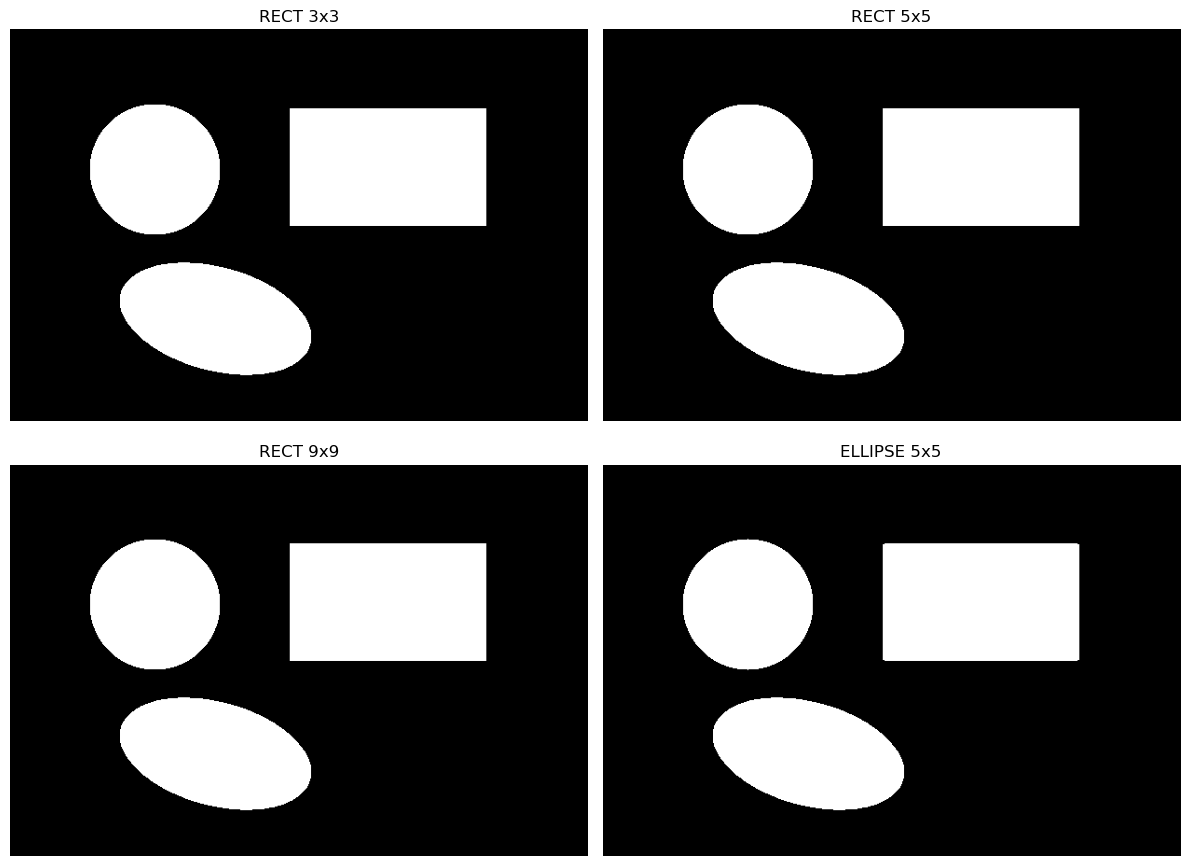

In [10]:
kernels = [
    ("RECT 3x3", cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))),
    ("RECT 5x5", cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))),
    ("RECT 9x9", cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))),
    ("ELLIPSE 5x5", cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))),
]

kernel_results = []
for name, k in kernels:
    result = cv2.morphologyEx(binary, cv2.MORPH_OPEN, k)
    kernel_results.append((result, name))

show_grid(kernel_results, cols=2, figsize=(12, 9))

### 1.5 WHY morphology works — Markdown answer

**Markdown-cell answer:** Erosion acts like a local minimum filter and shrinks white regions, so it removes small bright noise. Dilation acts like a local maximum filter and expands white regions. Opening = erosion → dilation, so it removes small bright noise while preserving the general shape of larger objects. Closing = dilation → erosion, so it fills small dark holes and connects small gaps without changing the overall object structure too much.

**Real-world example:** before sending a noisy camera frame to a downstream detector, opening can remove isolated sensor noise, while closing can fill small gaps in a detected mask. This is useful in surveillance, quality inspection and retail-analytics pipelines.

# Task 2 — Bitwise Operations & Image Histograms

## 2.1 Bitwise AND / OR / XOR / NOT

Two binary masks are created from a blank canvas. The operations are:

- **AND:** keeps pixels present in both masks.
- **OR:** keeps pixels present in either mask.
- **XOR:** keeps pixels present in exactly one mask.
- **NOT:** inverts a mask.

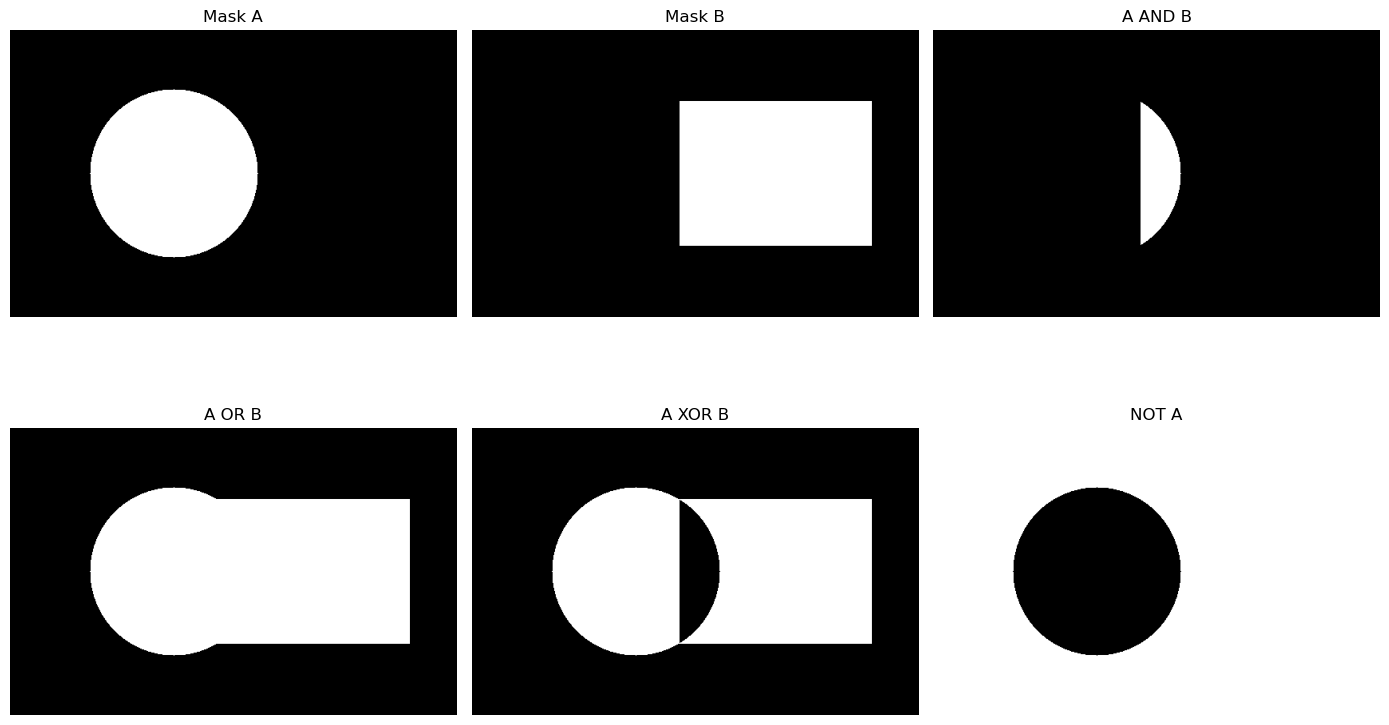

In [11]:
canvas_shape = (360, 560)

mask_a = np.zeros(canvas_shape, dtype=np.uint8)
mask_b = np.zeros(canvas_shape, dtype=np.uint8)

cv2.circle(mask_a, (205, 180), 105, 255, -1)
cv2.rectangle(mask_b, (260, 90), (500, 270), 255, -1)

bit_and = cv2.bitwise_and(mask_a, mask_b)
bit_or  = cv2.bitwise_or(mask_a, mask_b)
bit_xor = cv2.bitwise_xor(mask_a, mask_b)
bit_not = cv2.bitwise_not(mask_a)

show_grid([
    (mask_a, "Mask A"),
    (mask_b, "Mask B"),
    (bit_and, "A AND B"),
    (bit_or, "A OR B"),
    (bit_xor, "A XOR B"),
    (bit_not, "NOT A")
], cols=3, figsize=(14, 9))

## 2.2 Applied use-case: masked overlay

A practical use is selecting a region of interest (ROI). Here we create a circular ROI and blend it with a real image. In surveillance, the same idea can be used to keep only a camera zone such as an entrance or checkout area.

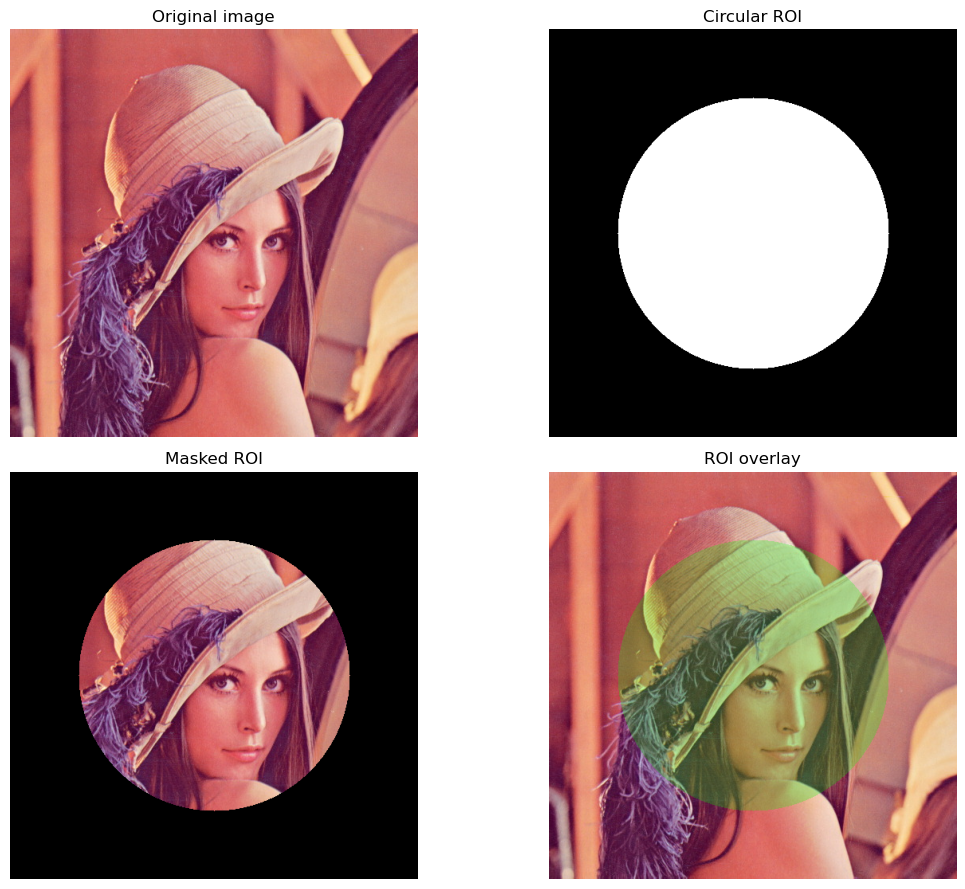

In [12]:
# Download OpenCV's public sample image for a realistic ROI example.
face_url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
face_path = download_file(face_url, IMAGES / "lena.jpg")
face_img = cv2.imread(str(face_path))

if face_img is None:
    raise RuntimeError("Could not read lena.jpg")

h2, w2 = face_img.shape[:2]
roi_mask = np.zeros((h2, w2), dtype=np.uint8)
cv2.circle(roi_mask, (w2 // 2, h2 // 2), min(h2, w2) // 3, 255, -1)

roi = cv2.bitwise_and(face_img, face_img, mask=roi_mask)

overlay = face_img.copy()
overlay[roi_mask > 0] = (0, 255, 0)
overlay = cv2.addWeighted(face_img, 0.75, overlay, 0.25, 0)

show_grid([
    (face_img, "Original image"),
    (roi_mask, "Circular ROI"),
    (roi, "Masked ROI"),
    (overlay, "ROI overlay")
], cols=2, figsize=(12, 9))

## 2.3 Grayscale & per-channel colour histograms

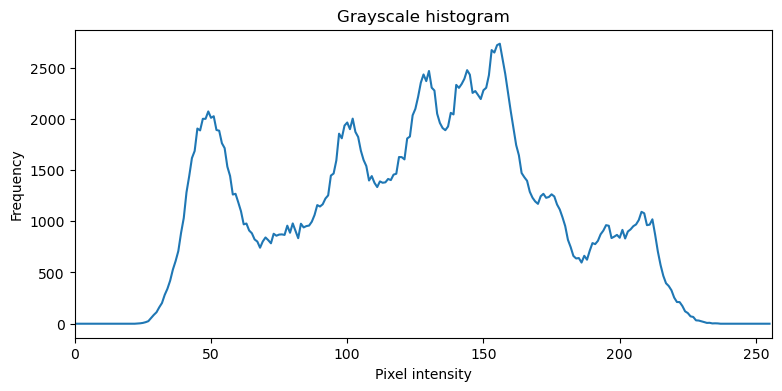

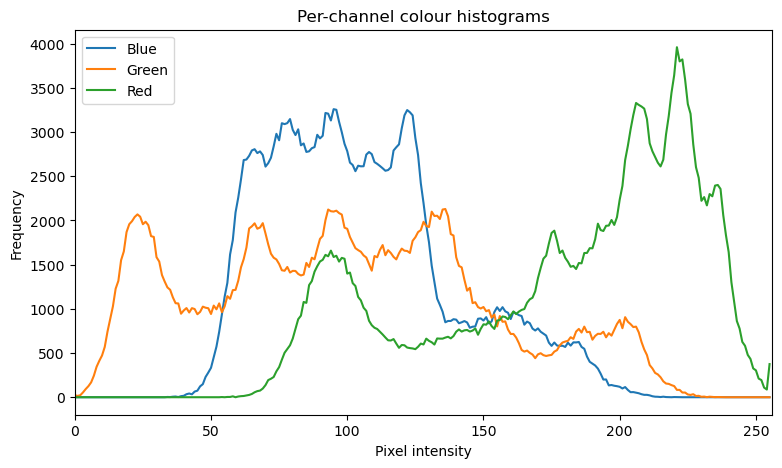

In [13]:
gray_face = cv2.cvtColor(face_img, cv2.COLOR_BGR2GRAY)

hist_gray = cv2.calcHist([gray_face], [0], None, [256], [0, 256])

plt.figure(figsize=(9, 4))
plt.plot(hist_gray)
plt.title("Grayscale histogram")
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])
plt.show()

channels = cv2.split(face_img)
channel_names = ["Blue", "Green", "Red"]

plt.figure(figsize=(9, 5))
for channel, name in zip(channels, channel_names):
    hist = cv2.calcHist([channel], [0], None, [256], [0, 256])
    plt.plot(hist, label=name)
plt.title("Per-channel colour histograms")
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])
plt.legend()
plt.show()

## 2.4 Brightness & contrast adjustment

Formula:

**new_pixel = alpha × pixel + beta**

- `alpha` controls contrast.
- `beta` controls brightness.

We create brighter and darker versions and compare their grayscale histograms.

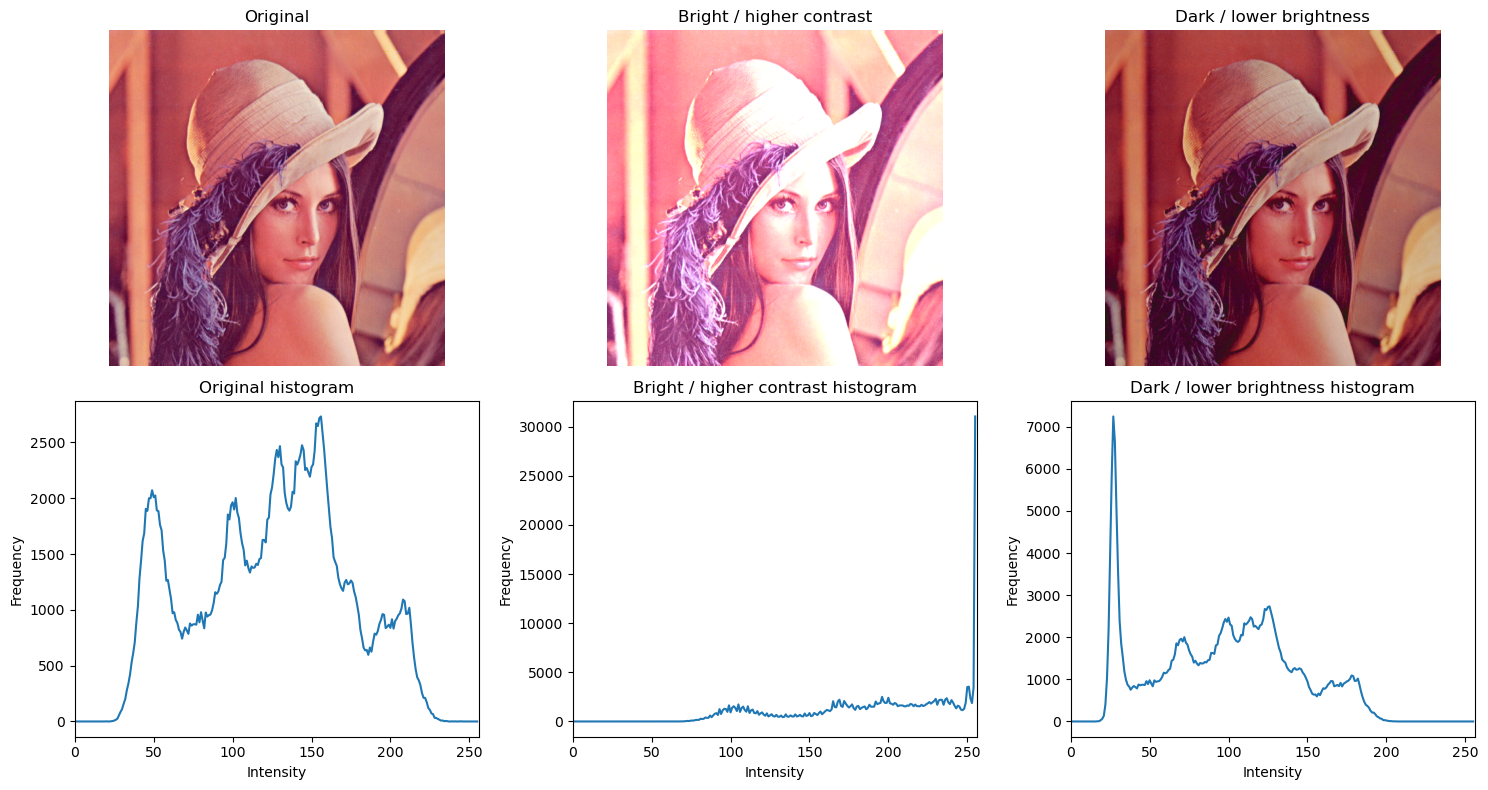

In [14]:
bright = cv2.convertScaleAbs(face_img, alpha=1.5, beta=30)
dark = cv2.convertScaleAbs(face_img, alpha=1.0, beta=-30)

versions = [
    ("Original", face_img),
    ("Bright / higher contrast", bright),
    ("Dark / lower brightness", dark)
]

plt.figure(figsize=(15, 8))
for i, (title, img) in enumerate(versions):
    ax1 = plt.subplot(2, 3, i + 1)
    ax1.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax1.set_title(title)
    ax1.axis("off")

    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hist = cv2.calcHist([g], [0], None, [256], [0, 256])

    ax2 = plt.subplot(2, 3, i + 4)
    ax2.plot(hist)
    ax2.set_title(title + " histogram")
    ax2.set_xlim([0, 256])
    ax2.set_xlabel("Intensity")
    ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## 2.5 WHY alpha/beta and histograms matter — Markdown answer

`alpha` changes the spread of intensity values, so increasing it generally increases contrast and decreasing it compresses contrast. `beta` shifts the whole intensity distribution left or right, changing brightness.

A histogram is useful because it shows whether an image is mostly dark, mostly bright, low-contrast, or spread across a wide intensity range. This diagnostic is useful before detection: if a camera frame is severely underexposed or overexposed, preprocessing may improve the visibility of faces or objects.

A practical rule is to avoid aggressive preprocessing that creates artificial edges or removes important visual information. The best settings depend on the camera and scene.

# Task 3 — Face Detection with YuNet (OpenCV 5.0)

YuNet is a compact CNN-based face detector. It returns a face bounding box, five facial landmarks and a confidence score.

## 3.1 Load the YuNet face detector

In [15]:
yunet_url = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
yunet_path = download_file(yunet_url, MODELS / "face_detection_yunet_2023mar.onnx")

detector = cv2.FaceDetectorYN.create(
    str(yunet_path),
    "",
    (320, 320),
    0.9,
    0.3,
    5000
)

print("YuNet loaded successfully.")

YuNet loaded successfully.


## 3.2 Detect on static images

The code below uses the downloaded sample face image. The helper is written so additional images can easily be added to `data/images`.

Faces detected: 1
Face 1: box=[207.8 182.5 145.9 206.9], score=0.909


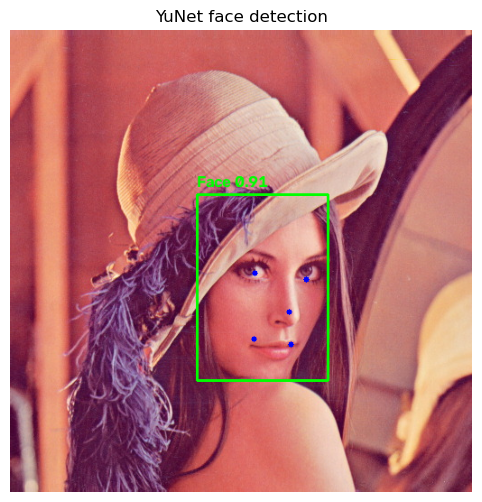

True

In [16]:
def detect_faces_yunet(img, score_threshold=0.9):
    detector.setScoreThreshold(score_threshold)
    h, w = img.shape[:2]
    detector.setInputSize((w, h))
    _, faces = detector.detect(img)
    return [] if faces is None else faces

def draw_yunet(img, faces):
    out = img.copy()
    for face in faces:
        x, y, bw, bh = face[:4].astype(int)
        score = float(face[-1])
        cv2.rectangle(out, (x, y), (x + bw, y + bh), (0, 255, 0), 2)

        # 5 landmarks: right eye, left eye, nose, right mouth, left mouth
        pts = face[4:14].reshape(5, 2).astype(int)
        for px, py in pts:
            cv2.circle(out, (px, py), 3, (255, 0, 0), -1)

        cv2.putText(out, f"Face {score:.2f}", (x, max(20, y - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    return out

faces = detect_faces_yunet(face_img, 0.9)
annotated_face = draw_yunet(face_img, faces)

print("Faces detected:", len(faces))
for i, face in enumerate(faces, 1):
    print(f"Face {i}: box={face[:4].round(1)}, score={face[-1]:.3f}")

show(annotated_face, "YuNet face detection", figsize=(8, 6))
cv2.imwrite(str(OUTPUTS / "06_yunet_face_detection.jpg"), annotated_face)

### 3.2 — Additional image support

Put 3–4 face photographs in `data/images` and run the next cell. For each image, the detector prints the number of detected faces and draws boxes, landmarks and confidence scores.

Images processed: 2


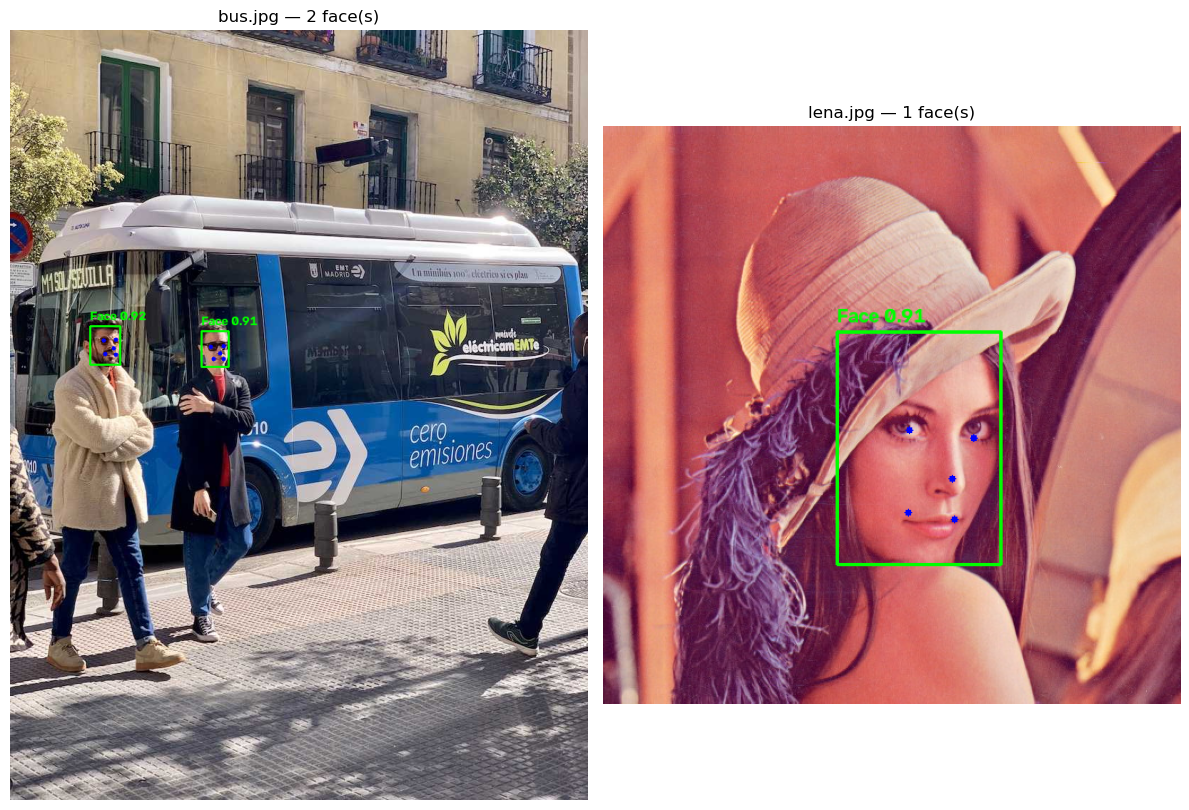

In [17]:
face_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
face_files = [
    p for p in IMAGES.iterdir()
    if p.suffix.lower() in face_extensions and p.name != "morphology_test.png"
]

results = []
for p in face_files:
    img = cv2.imread(str(p))
    if img is None:
        continue
    fs = detect_faces_yunet(img, 0.9)
    out = draw_yunet(img, fs)
    results.append((out, f"{p.name} — {len(fs)} face(s)"))

print("Images processed:", len(results))
if results:
    show_grid(results[:6], cols=2, figsize=(12, 12))
else:
    print("No extra readable face images were found.")

## 3.3 Real-time face detection on webcam

Run this cell in a local Jupyter/VS Code environment. Press **q** to stop.

The notebook reports an approximate FPS value based on processed frames.

In [18]:
# OPTIONAL WEBCAM CELL
# Press q in the OpenCV window to stop.

def run_yunet_webcam(camera_index=0):
    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        print("Webcam unavailable. Use a video file instead.")
        return

    frame_count = 0
    t0 = time.time()

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        fs = detect_faces_yunet(frame, 0.7)
        out = draw_yunet(frame, fs)

        frame_count += 1
        elapsed = max(time.time() - t0, 1e-6)
        fps = frame_count / elapsed
        cv2.putText(out, f"FPS: {fps:.1f}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)

        cv2.imshow("YuNet Face Detection - press q to quit", out)
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

    cap.release()
    cv2.destroyAllWindows()

# Uncomment to run:
# run_yunet_webcam(0)

## 3.4 Score-threshold experiment + privacy use-case

We compare thresholds **0.5, 0.7 and 0.9**. Lower thresholds are more sensitive but can produce more false positives. Higher thresholds are stricter and can miss weak/partially occluded faces.

After detection, a simple privacy filter can blur each detected face region.

threshold=0.5 -> 1 face(s)
threshold=0.7 -> 1 face(s)
threshold=0.9 -> 1 face(s)


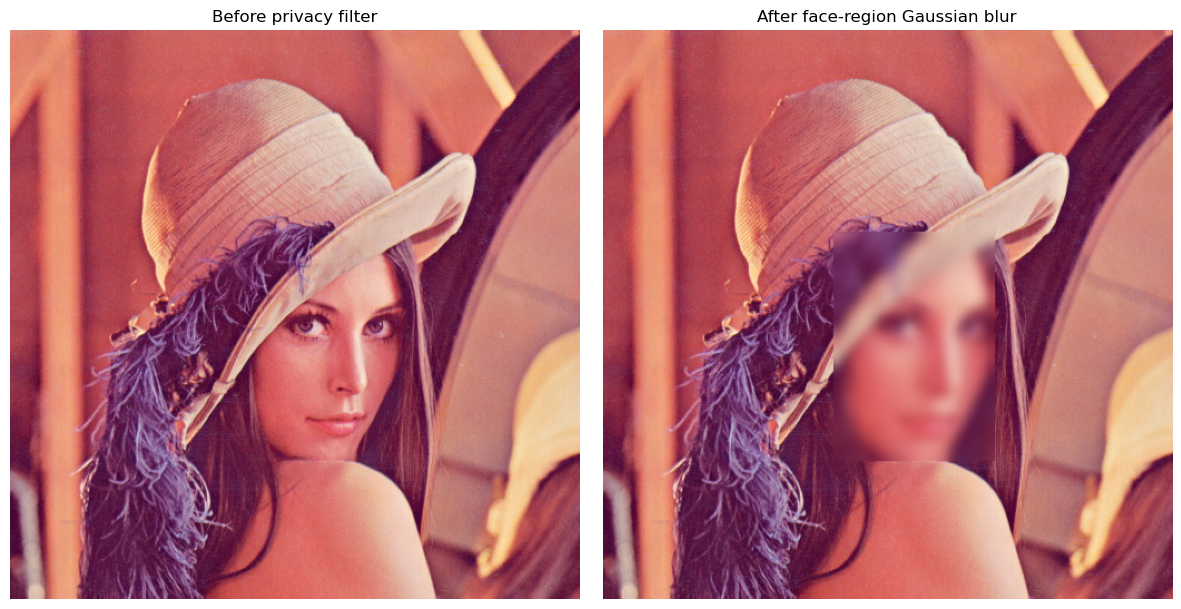

Threshold summary: [(0.5, 1), (0.7, 1), (0.9, 1)]


In [19]:
thresholds = [0.5, 0.7, 0.9]
threshold_results = []

for t in thresholds:
    fs = detect_faces_yunet(face_img, t)
    threshold_results.append((t, len(fs)))
    print(f"threshold={t:.1f} -> {len(fs)} face(s)")

# Practical anonymisation / privacy blur
faces_privacy = detect_faces_yunet(face_img, 0.7)
privacy = face_img.copy()

for face in faces_privacy:
    x, y, bw, bh = face[:4].astype(int)
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(privacy.shape[1], x + bw), min(privacy.shape[0], y + bh)
    if x2 > x1 and y2 > y1:
        roi = privacy[y1:y2, x1:x2]
        privacy[y1:y2, x1:x2] = cv2.GaussianBlur(roi, (31, 31), 0)

show_grid([
    (face_img, "Before privacy filter"),
    (privacy, "After face-region Gaussian blur")
], cols=2, figsize=(12, 6))

print("Threshold summary:", threshold_results)

## 3.5 WHY YuNet — Markdown answer

YuNet is a modern CNN-based face detector included in the OpenCV Zoo ecosystem. It is designed to be compact and fast enough for practical CPU/edge scenarios. Unlike classical hand-crafted face detectors, YuNet learns visual features from training data and can return a bounding box, confidence and five facial landmarks in one forward pass.

The confidence threshold controls the precision/recall trade-off. For a security camera, a lower threshold may improve recall but can increase false alarms; for a photo-tagging application, a higher threshold may be preferable when false positives are more costly. The correct value should be selected using representative validation images rather than choosing it arbitrarily.

# Task 4 — Object Detection with YOLOv8

YOLOv8 is a single-stage object detector. The Nano (`yolov8n.pt`) model is lightweight and pretrained on the COCO dataset.

## 4.1 Load pretrained YOLOv8 and run on static images

In [20]:
from ultralytics import YOLO

# Ultralytics downloads yolov8n.pt automatically on first use if it is not present.
model = YOLO("yolov8n.pt")
print("YOLOv8 model loaded.")

YOLOv8 model loaded.


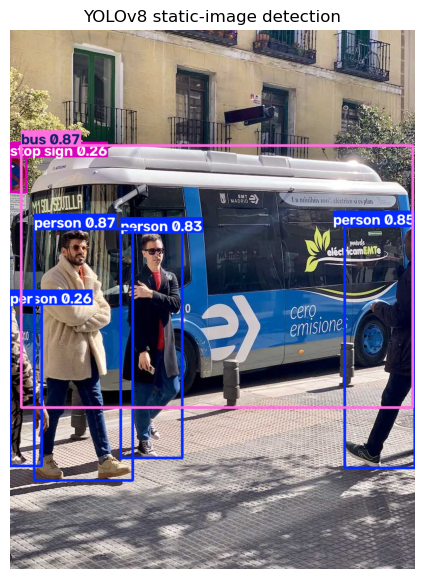

Total detections: 6
bus             confidence=0.873 box=[       22.9       231.3         805       756.8]
person          confidence=0.866 box=[       48.6       398.6       245.3       902.7]
person          confidence=0.853 box=[      669.5       392.2       809.7         877]
person          confidence=0.825 box=[      221.5       405.8         345       857.5]
person          confidence=0.261 box=[          0       550.5          63       873.4]
stop sign       confidence=0.255 box=[        0.1       254.5        32.6       324.9]


True

In [21]:
bus_url = "https://ultralytics.com/images/bus.jpg"
bus_path = download_file(bus_url, IMAGES / "bus.jpg")
bus_img = cv2.imread(str(bus_path))

if bus_img is None:
    raise RuntimeError("Could not read bus.jpg")

yolo_results = model.predict(source=str(bus_path), conf=0.25, verbose=False)

result_plot = yolo_results[0].plot()
show(result_plot, "YOLOv8 static-image detection", figsize=(12, 7))

# Print detections
names = model.names
boxes = yolo_results[0].boxes

print("Total detections:", len(boxes))
for cls_id, conf, xyxy in zip(
    boxes.cls.cpu().numpy().astype(int),
    boxes.conf.cpu().numpy(),
    boxes.xyxy.cpu().numpy()
):
    print(f"{names[cls_id]:15s} confidence={conf:.3f} box={xyxy.round(1)}")

cv2.imwrite(str(OUTPUTS / "07_yolov8_static.jpg"), result_plot)

## 4.2 Real-time YOLO on webcam

This cell follows the project specification using `cv2.VideoCapture(0)`. Press **q** to stop.

If a webcam is unavailable, use the supplied `bus.jpg` or replace `VIDEO_PATH` with a local MP4/MOV file.

In [22]:
# OPTIONAL REAL-TIME YOLO CELL

def run_yolo_webcam(camera_index=0, conf=0.25):
    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        print("Webcam unavailable.")
        return

    count = 0
    t0 = time.time()

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        result = model.predict(frame, conf=conf, verbose=False)[0]
        annotated = result.plot()

        count += 1
        fps = count / max(time.time() - t0, 1e-6)
        cv2.putText(annotated, f"FPS: {fps:.1f}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)

        cv2.imshow("YOLOv8 - press q to quit", annotated)
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

    cap.release()
    cv2.destroyAllWindows()

# Uncomment to run:
# run_yolo_webcam(0, conf=0.25)

## 4.3 Confidence & IoU threshold tuning

Required confidence values: **0.25, 0.50, 0.75**

Required IoU values: **0.30, 0.50, 0.70**

We first compare confidence thresholds, then IoU thresholds. A higher confidence threshold usually reduces low-confidence detections. IoU is used by Non-Max Suppression (NMS) to decide when overlapping boxes should be treated as duplicates.

In [23]:
# Confidence experiment
conf_values = [0.25, 0.50, 0.75]
conf_summary = []

for conf in conf_values:
    r = model.predict(source=str(bus_path), conf=conf, verbose=False)[0]
    count = len(r.boxes)
    conf_summary.append({"confidence": conf, "detections": count})
    print(f"confidence={conf:.2f} -> {count} detections")

pd.DataFrame(conf_summary)

confidence=0.25 -> 6 detections
confidence=0.50 -> 4 detections
confidence=0.75 -> 4 detections


,confidence,detections
0,0.25,6
1,0.50,4
2,0.75,4


In [24]:
# IoU experiment
iou_values = [0.30, 0.50, 0.70]
iou_summary = []

for iou in iou_values:
    r = model.predict(source=str(bus_path), conf=0.25, iou=iou, verbose=False)[0]
    count = len(r.boxes)
    iou_summary.append({"IoU": iou, "detections": count})
    print(f"IoU={iou:.2f} -> {count} detections")

pd.DataFrame(iou_summary)

IoU=0.30 -> 6 detections
IoU=0.50 -> 6 detections
IoU=0.70 -> 6 detections


,IoU,detections
0,0.3,6
1,0.5,6
2,0.7,6


### Demonstrating duplicate-box cleanup

A lower IoU NMS threshold is stricter about overlapping boxes and is more likely to suppress boxes that overlap substantially. A higher IoU threshold allows more overlapping boxes to survive. The exact result depends on the image and model predictions.

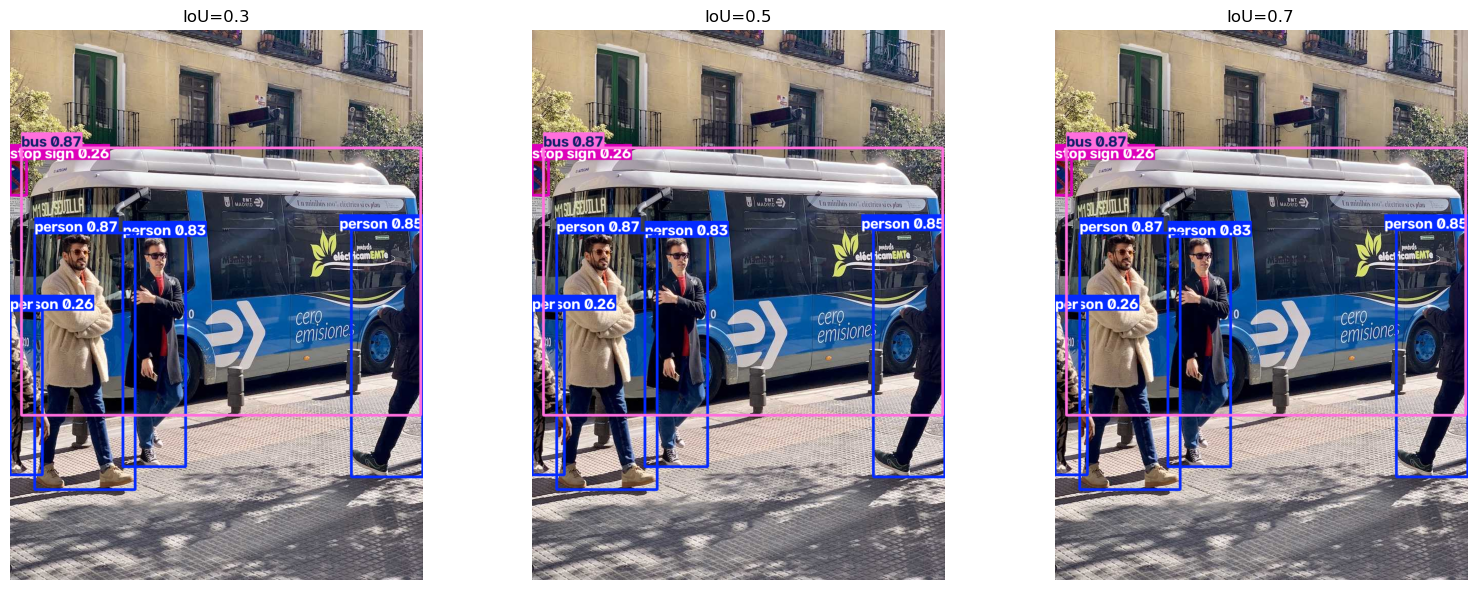

In [25]:
figures = []
for iou in iou_values:
    r = model.predict(source=str(bus_path), conf=0.25, iou=iou, verbose=False)[0]
    figures.append((r.plot(), f"IoU={iou}"))

show_grid(figures, cols=3, figsize=(16, 6))

## 4.4 Per-class detection summary

Across the test image, we count how many detections belong to each COCO class.

,Class,Detections
0,person,4
1,bus,1
2,stop sign,1


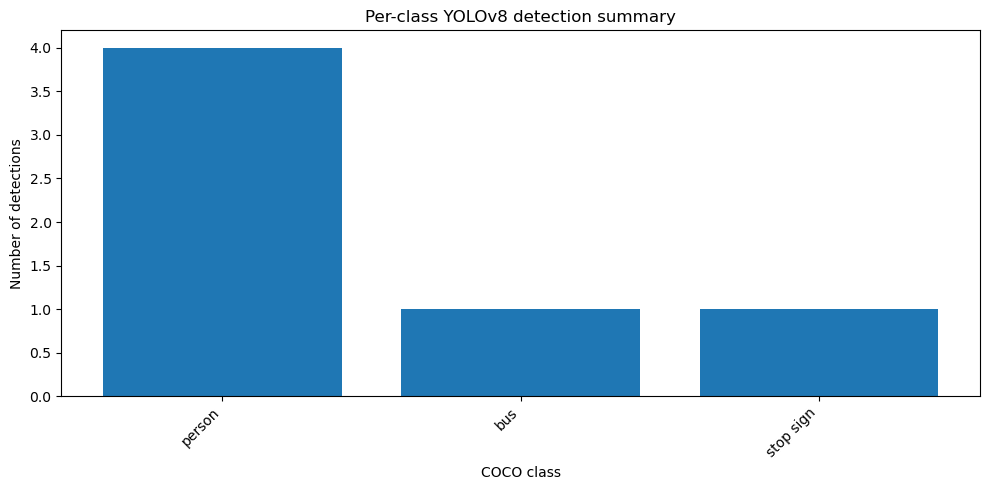

In [26]:
r = model.predict(source=str(bus_path), conf=0.25, verbose=False)[0]

class_counts = {}
for cls_id in r.boxes.cls.cpu().numpy().astype(int):
    class_name = model.names[cls_id]
    class_counts[class_name] = class_counts.get(class_name, 0) + 1

class_df = pd.DataFrame(
    sorted(class_counts.items(), key=lambda x: x[1], reverse=True),
    columns=["Class", "Detections"]
)

display(class_df)

plt.figure(figsize=(10, 5))
plt.bar(class_df["Class"], class_df["Detections"])
plt.title("Per-class YOLOv8 detection summary")
plt.xlabel("COCO class")
plt.ylabel("Number of detections")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 4.5 WHY YOLO generalises — Markdown answer

YOLO uses a single-stage detection design: the image is processed in one forward pass to predict bounding boxes, class probabilities and confidence scores, followed by Non-Max Suppression to remove duplicate detections.

YOLOv8 Nano is fast because it is much smaller than larger YOLOv8 variants, but the trade-off is lower accuracy on difficult scenes. Its COCO pretraining covers 80 object categories, allowing one model to recognise many common objects without manually creating a separate detector for every class.

Possible causes of missed/misclassified objects include small object size, occlusion, unusual viewpoints, motion blur, poor lighting, objects outside the training distribution and low confidence thresholds.

# Task 5 — Integrated Pipeline & Final Comparison

## 5.1 Build the unified pipeline

The combined pipeline demonstrates:
1. **YuNet face detection** in green.
2. **YOLOv8 object detection** with class labels and confidence.
3. Both annotation layers are overlaid on the same frame.

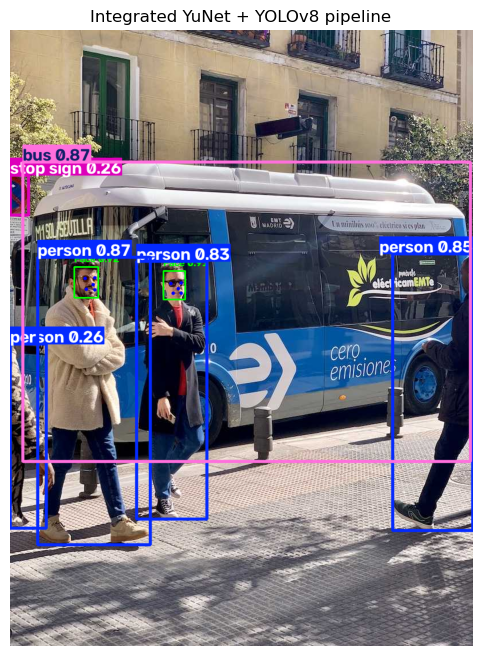

YuNet faces: 2
YOLO objects: 6


In [27]:
def unified_pipeline(frame, face_threshold=0.7, yolo_conf=0.25, yolo_iou=0.5):
    # Face layer
    face_boxes = detect_faces_yunet(frame, face_threshold)
    output = draw_yunet(frame, face_boxes)

    # Object layer
    yolo_result = model.predict(
        source=frame,
        conf=yolo_conf,
        iou=yolo_iou,
        verbose=False
    )[0]

    output = yolo_result.plot(img=output)

    return output, face_boxes, yolo_result

combined, detected_faces, detected_objects = unified_pipeline(
    bus_img, face_threshold=0.7, yolo_conf=0.25, yolo_iou=0.5
)

show(combined, "Integrated YuNet + YOLOv8 pipeline", figsize=(13, 8))
cv2.imwrite(str(OUTPUTS / "08_integrated_pipeline.jpg"), combined)

print("YuNet faces:", len(detected_faces))
print("YOLO objects:", len(detected_objects.boxes))

## 5.2 Morphological pre-cleaning

A light opening operation is useful for reducing small isolated bright noise in a binary mask. For a real detector, however, preprocessing should be validated carefully because excessive morphology can erase small objects or distort edges.

The following cell demonstrates opening on a noisy binary camera-like frame.

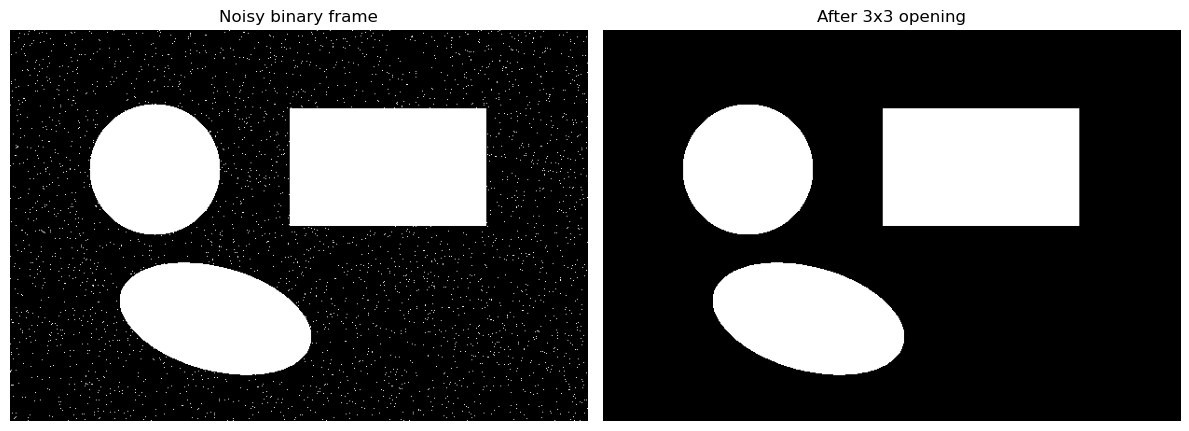

In [28]:
# Build a noisy binary mask
clean_mask = binary.copy()
noise_mask = rng.random(binary.shape) < 0.015
clean_mask[noise_mask] = 255

opened = cv2.morphologyEx(
    clean_mask,
    cv2.MORPH_OPEN,
    cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
)

show_grid([
    (clean_mask, "Noisy binary frame"),
    (opened, "After 3x3 opening")
], cols=2, figsize=(12, 5))

### Optional detector-quality comparison on the synthetic mask

For a fair detection-quality test, use a real noisy frame with known objects. On this synthetic mask, we demonstrate only the preprocessing effect; it is not presented as an accuracy benchmark for YOLO.

## 5.3 FPS benchmarking

We measure:
- YuNet face detection alone
- YOLOv8 alone
- Full combined pipeline

The benchmark uses the same repeated static frame. **FPS is hardware-dependent**, so your values will differ from another computer.

,Pipeline,Frames,Time (s),Approx. FPS
0,YuNet face detector,100,9.828,10.18
1,YOLOv8 only,100,5.998,16.67
2,YuNet + YOLOv8,100,17.936,5.58


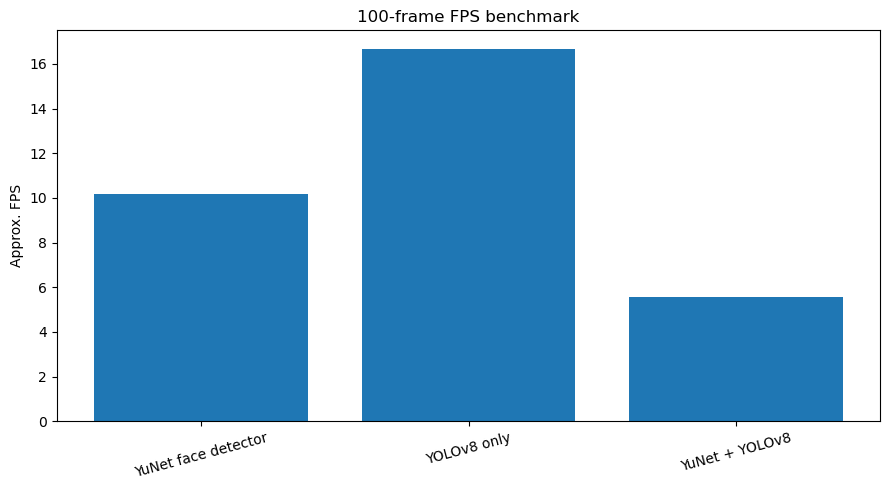

In [29]:
def benchmark_pipeline(frame, mode="yunet", frames=100):
    t0 = time.perf_counter()

    for _ in range(frames):
        if mode == "yunet":
            detect_faces_yunet(frame, 0.7)
        elif mode == "yolo":
            model.predict(frame, conf=0.25, verbose=False)
        elif mode == "combined":
            unified_pipeline(frame, face_threshold=0.7, yolo_conf=0.25, yolo_iou=0.5)
        else:
            raise ValueError("mode must be yunet, yolo or combined")

    elapsed = time.perf_counter() - t0
    return frames / max(elapsed, 1e-9), elapsed

# 100-frame benchmark as required by the project sheet.
benchmark_rows = []
for mode, label in [
    ("yunet", "YuNet face detector"),
    ("yolo", "YOLOv8 only"),
    ("combined", "YuNet + YOLOv8")
]:
    fps, elapsed = benchmark_pipeline(bus_img, mode=mode, frames=100)
    benchmark_rows.append({
        "Pipeline": label,
        "Frames": 100,
        "Time (s)": round(elapsed, 3),
        "Approx. FPS": round(fps, 2)
    })

benchmark_df = pd.DataFrame(benchmark_rows)
display(benchmark_df)

plt.figure(figsize=(9, 5))
plt.bar(benchmark_df["Pipeline"], benchmark_df["Approx. FPS"])
plt.title("100-frame FPS benchmark")
plt.ylabel("Approx. FPS")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 5.4 Final results comparison table

The table compares all major techniques from Tasks 1–4.

In [30]:
comparison = pd.DataFrame([
    {
        "Technique": "Morphology",
        "Type": "Classical",
        "What it detects/does": "Noise, holes, gaps and shape cleanup in binary masks",
        "Lighting robustness": "Low–Medium; depends strongly on thresholding",
        "Approx. FPS": "Very high / CPU-friendly",
        "Best use case": "Mask cleanup before segmentation/detection"
    },
    {
        "Technique": "Bitwise + Histograms",
        "Type": "Classical",
        "What it detects/does": "ROI masking and intensity distribution analysis",
        "Lighting robustness": "Low–Medium; useful for diagnosing lighting",
        "Approx. FPS": "Very high / CPU-friendly",
        "Best use case": "ROI extraction and image-quality diagnostics"
    },
    {
        "Technique": "YuNet",
        "Type": "Deep Learning",
        "What it detects/does": "Faces + 5 facial landmarks",
        "Lighting robustness": "Medium–High depending on scene",
        "Approx. FPS": "Hardware-dependent; generally lightweight",
        "Best use case": "Real-time face detection / privacy filtering"
    },
    {
        "Technique": "YOLOv8n",
        "Type": "Deep Learning",
        "What it detects/does": "80 COCO object classes",
        "Lighting robustness": "Medium–High depending on training/domain",
        "Approx. FPS": "Hardware-dependent; optimized for speed",
        "Best use case": "General multi-class object detection"
    }
])

display(comparison)
comparison.to_csv(OUTPUTS / "final_comparison.csv", index=False)

,Technique,Type,What it detects/does,Lighting robustness,Approx. FPS,Best use case
0,Morphology,Classical,"Noise, holes, gaps and shape cleanup in binary...",Low–Medium; depends strongly on thresholding,Very high / CPU-friendly,Mask cleanup before segmentation/detection
1,Bitwise + Histograms,Classical,ROI masking and intensity distribution analysis,Low–Medium; useful for diagnosing lighting,Very high / CPU-friendly,ROI extraction and image-quality diagnostics
2,YuNet,Deep Learning,Faces + 5 facial landmarks,Medium–High depending on scene,Hardware-dependent; generally lightweight,Real-time face detection / privacy filtering
3,YOLOv8n,Deep Learning,80 COCO object classes,Medium–High depending on training/domain,Hardware-dependent; optimized for speed,General multi-class object detection


## 5.5 Reflection — Markdown answer

### Which combination gives the best accuracy-to-compute trade-off?

For a real-time monitoring system, I would use **light classical preprocessing only when the camera feed is noisy**, followed by a compact deep-learning detector. YuNet is appropriate when the task is specifically face detection, while YOLOv8n is appropriate when multiple object classes must be detected.

### What would I change for a low-power edge device?

I would:
- keep the YOLO Nano model or use an even smaller/quantized deployment model;
- reduce input resolution if accuracy remains acceptable;
- process every second or third frame when the scene changes slowly;
- avoid expensive preprocessing unless it improves measured detection quality;
- use hardware acceleration where supported;
- tune confidence and IoU thresholds using representative validation footage.

### What would I change for a cloud server?

On a cloud GPU, I would consider a larger YOLO model for higher accuracy, increase input resolution for small objects, batch frames when latency permits, and benchmark accuracy against latency rather than maximising FPS alone.

### Final conclusion

Classical image processing is fast and useful for preparing or analysing images, but it does not replace learned object/face detectors. YuNet provides a focused face detector with landmarks, while YOLOv8 provides broad multi-class detection. The integrated pipeline combines the strengths of both approaches and mirrors practical edge-computer-vision systems.